<!--
Copyright © 2026 The Trustees of Indiana University and contributors.
This work is licensed under the Creative Commons Attribution-NonCommercial 4.0 International License (CC BY-NC 4.0).
You may use, share, and adapt this work for non-commercial purposes, subject to the terms of the license and appropriate attribution.
See the LICENSE file in the root of this repository for the full license terms.
https://creativecommons.org/licenses/by-nc/4.0/
-->

# Empirical Parameters Calibration for Event Type distribution


## Folder placement

- **Current location**: `analyses/calibration/activity/`

## 1) Data used

Describe the empirical data source(s) in enough detail for a future reader to obtain or reproduce it.

- **Dataset name or source**: Bluesky firehose
- **Time range**: 2025-05-01
- **Access / documentation link**: Data collection was done with [`osome-iu/osome-bluesky-streamer`](https://github.com/osome-iu/osome-bluesky-streamer), an archive can be requested by contacting [OSoMe IU](https://osome.iu.edu/resources/data-resources).
- **Raw files / tables used**: `2025-05-01.json.gz`
- **Preprocessing steps**: 
    1. Read `type` and `action` from each event in the firehose
    2. Store with `author`, timestamp, and is_self

In [ ]:
import gzip
import json
import logging

from tqdm import tqdm
from datetime import datetime

def get_rtype(rec: dict) -> str | None:
    return rec.get("type") or rec.get("$type")

def extract_embed_post_uri(rec: dict) -> str | None:
    embed = rec.get("embed")
    if not isinstance(embed, dict):
        return None

    record = embed.get("record")
    if isinstance(record, dict):
        inner = record.get("record") if isinstance(record.get("record"), dict) else record
        uri = inner.get("uri") if isinstance(inner, dict) else None
        if isinstance(uri, str) and "/app.bsky" in uri:
            return uri

    return None

def extract_did(uri):
    return uri.split("/")[2]

def classify_post(rec: dict) -> str:
    if rec.get("reply"):
        return "reply"

    embed = rec.get("embed")
    if isinstance(embed, dict):
        etype = embed.get("$type", "")
        if etype in ("app.bsky.embed.record", "app.bsky.embed.recordWithMedia"):
            return "quote"
        if "record" in embed:
            return "quote"

    return "post"

def classify_action(rec: dict, rtype: str | None = None) -> str | None:
    rtype = rtype or get_rtype(rec)
    if rtype == "app.bsky.feed.like":
        return "like"
    if rtype == "app.bsky.feed.repost":
        return "repost"
    if rtype == "app.bsky.feed.post":
        return classify_post(rec)
    return None

def is_self(event, event_type):
    if event_type == "quote":
        return extract_did(extract_embed_post_uri(event)) == event["author"]
    
    if event_type == "reply":
        return extract_did(event["reply"]["parent"]["uri"]) == event["author"]
    
    if event_type == "repost" or event_type == "like":
        return extract_did(event["subject"]["uri"]) == event["author"]
    
    return False

def get_timestamps(path):
    dates = []
    types = []
    actions = []
    dids = []
    is_selfs = []
    with gzip.open(path, "rt") as f:
        for line in tqdm(f):
            try:
                event = json.loads(line)

                ts = datetime.strptime(event["commit_time_str"], "%Y-%m-%dT%H:%M:%S.%fZ")
                dates.append(int(ts.timestamp() * 1000))

                type_ = classify_action(event)
                types.append(type_)
                actions.append(event["action"])
                dids.append(event["author"])

                is_selfs.append(is_self(event, type_) if event["action"] == "create" else None)


            except json.JSONDecodeError as e:
                logging.debug(f"Error in {path}:\n{e}")

    return dates, types, actions, dids, is_selfs

path = "YOUR_PATH_HERE/2025-05-01.json.gz"

timestamps, types, actions, dids, is_selfs = get_timestamps(path)

with gzip.open("timestamps_bsky_users.csv.gz", "wt") as f:
    f.write(f"timestamp,type,action,did,is_self\n")
    for ts, ty, action, did, iss in zip(timestamps, types, actions, dids, is_selfs):
        f.write(f"{ts},{ty},{action},{did},{iss}\n")

## 2) New feature contribution

Explain what new feature this calibration adds and where it lives in the codebase.

- **Component**: TODO (e.g., `clock`)
- **What it adds**: Allows for sampling the distribution of event types (post, repost, like, reply, quote) for each user.
- **Code location**: TODO (file path + key classes/functions, permalink, etc.)
- **Design rationale**: Although there is a slight correlation between activity level and the distribution, this is ignored for simplicity.


## 2b) References & provenance

Make the calibration traceable to specific code and design. Complete one or more of items below.

- **Repo + branch/tag**: TODO (e.g., `main`, `feature/clock-calibration`, release tag)
- **Commit SHA(s)**: TODO (full 40-char SHA)


## 3) Analysis / calibration method

Document how you transform the data into model parameters or behaviors.

- **Features extracted**: 
- **Estimation / fitting**: TODO (method, assumptions)
- **Validation**: TODO (plots, statistics, sanity checks)


In [ ]:
import pandas as pd

df = pd.read_csv("timestamps_bsky_users.csv.gz", usecols=["action", "type", "did"])
df = df[(df["action"] == "create") & (~df["type"].isna())]
df

,type,action,did
0,like,create,did:plc:65dh52hlkjx5fiolqii7vbov
1,repost,create,did:plc:rjhmgjwpshhm5fbvu3obzjox
2,like,create,did:plc:i5xljap2s26br3gobibv5erp
3,like,create,did:plc:hoggkvllepdburz27lrs4k7q
4,like,create,did:plc:rrqtg4ydogwtgw3uq4rhhjkw
...,...,...,...
41174519,repost,create,did:plc:7bv5egpqrrvnlzolqbhr6tdx
41174520,like,create,did:plc:c22e3tr73pkocmna4bxx7rc4
41174522,repost,create,did:plc:4kyfqilr7azavvpmkpj5nppa
41174523,repost,create,did:plc:avwklydgsfzvhamnq4nk5pkp


In [2]:
limit = 500

types = ["like", "repost", "reply", "post", "quote"]

counts = df.groupby(["did", "type"]).size().unstack(fill_value=0)
counts = counts.reindex(columns=types, fill_value=0)

counts["total"] = counts.sum(axis=1)
counts = counts[counts["total"] < limit]

props = counts[types].div(counts["total"], axis=0)
props["total"] = counts["total"]

# get mean and std for each bin of total activity
grouped = props.groupby("total")[types]
means = grouped.mean().sort_index()
stds = grouped.std(ddof=0).sort_index()  # ddof=0 to match np.std default

x = means.index.to_numpy()
likes_m_y, reposts_m_y, replies_m_y, posts_m_y, quotes_m_y = (means[t].to_numpy() for t in types)
likes_s_y, reposts_s_y, replies_s_y, posts_s_y, quotes_s_y = (stds[t].to_numpy() for t in types)

# get mean and std across all users
type_m = props[types].mean()
type_s = props[types].std(ddof=0)

likes_m, reposts_m, replies_m, posts_m, quotes_m = tuple(type_m[t] for t in types)
likes_s, reposts_s, replies_s, posts_s, quotes_s = tuple(type_s[t] for t in types)

### Check if there is a correlation between activity level and the event distribution for each type

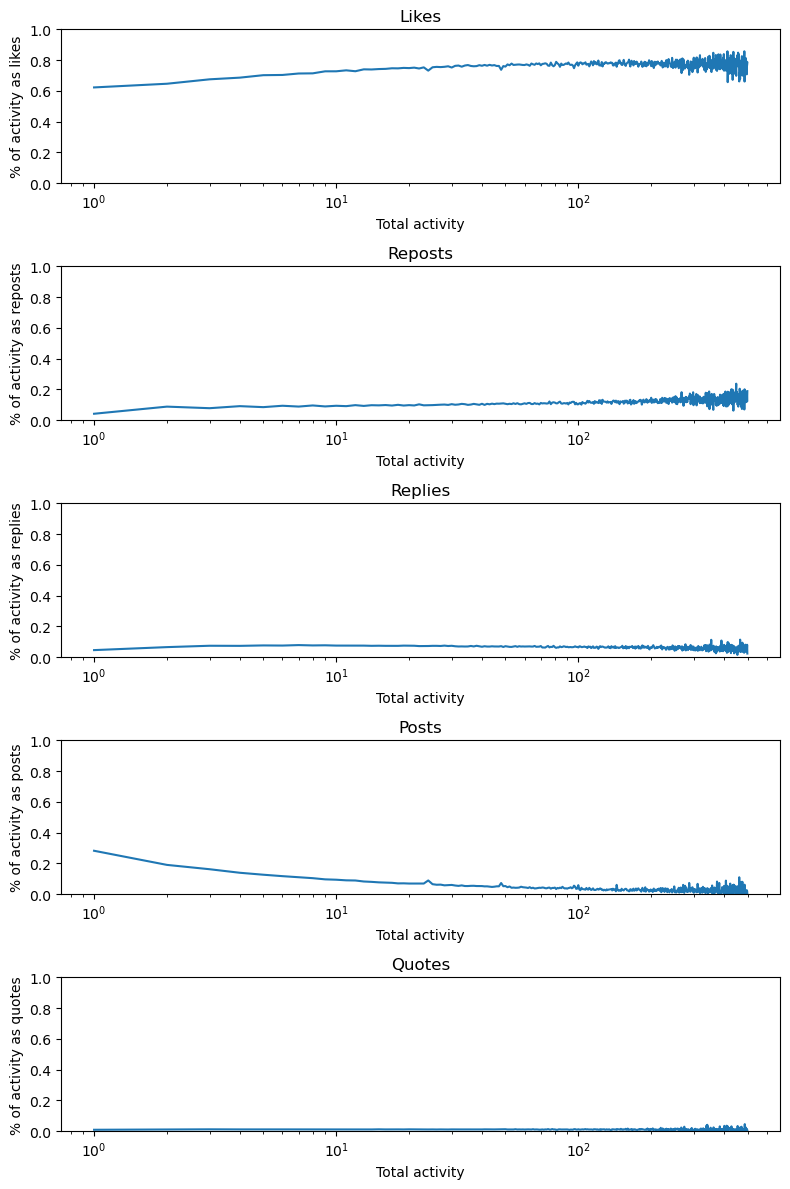

In [3]:
import matplotlib.pyplot as plt

fig, (ax1, ax2, ax3, ax4, ax5) = plt.subplots(5, 1, figsize=(8, 12))

ax1.plot(x, likes_m_y)
ax1.set_title("Likes")
ax1.set_xlabel("Total activity")
ax1.set_ylabel("% of activity as likes")
ax1.set_xscale("log")
ax1.set_ylim(0, 1)

ax2.plot(x, reposts_m_y)
ax2.set_title("Reposts")
ax2.set_xlabel("Total activity")
ax2.set_ylabel("% of activity as reposts")
ax2.set_xscale("log")
ax2.set_ylim(0, 1)

ax3.plot(x, replies_m_y)
ax3.set_title("Replies")
ax3.set_xlabel("Total activity")
ax3.set_ylabel("% of activity as replies")
ax3.set_xscale("log")
ax3.set_ylim(0, 1)

ax4.plot(x, posts_m_y)
ax4.set_title("Posts")
ax4.set_xlabel("Total activity")
ax4.set_ylabel("% of activity as posts")
ax4.set_xscale("log")
ax4.set_ylim(0, 1)

ax5.plot(x, quotes_m_y)
ax5.set_title("Quotes")
ax5.set_xlabel("Total activity")
ax5.set_ylabel("% of activity as quotes")
ax5.set_xscale("log")
ax5.set_ylim(0, 1)

plt.tight_layout()
plt.show()

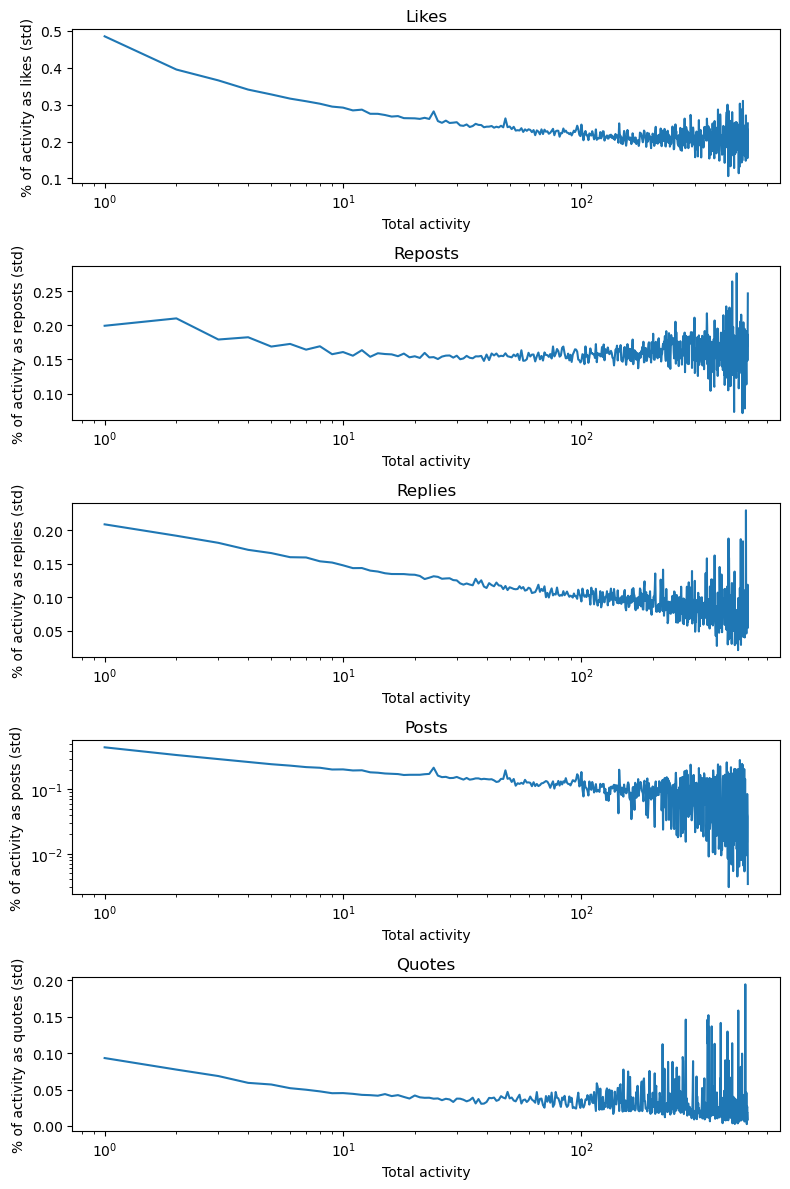

In [4]:
fig, (ax1, ax2, ax3, ax4, ax5) = plt.subplots(5, 1, figsize=(8, 12))

ax1.plot(x, likes_s_y)
ax1.set_title("Likes")
ax1.set_xlabel("Total activity")
ax1.set_ylabel("% of activity as likes (std)")
ax1.set_xscale("log")

ax2.plot(x, reposts_s_y)
ax2.set_title("Reposts")
ax2.set_xlabel("Total activity")
ax2.set_ylabel("% of activity as reposts (std)")
ax2.set_xscale("log")

ax3.plot(x, replies_s_y)
ax3.set_title("Replies")
ax3.set_xlabel("Total activity")
ax3.set_ylabel("% of activity as replies (std)")
ax3.set_xscale("log")

ax4.plot(x, posts_s_y)
ax4.set_yscale("log")
ax4.set_title("Posts")
ax4.set_xlabel("Total activity")
ax4.set_ylabel("% of activity as posts (std)")
ax4.set_xscale("log")

ax5.plot(x, quotes_s_y)
ax5.set_title("Quotes")
ax5.set_xlabel("Total activity")
ax5.set_ylabel("% of activity as quotes (std)")
ax5.set_xscale("log")

plt.tight_layout()
plt.show()

In [5]:
import numpy as np

# there is a small correlation, but we ignore this for simplicity
def gen_dist(events):
    event_p = np.zeros(5)
    means = [likes_m, posts_m, reposts_m, replies_m, quotes_m]
    stds = [likes_s, posts_s, reposts_s, replies_s, quotes_s]

    for i, (m, s) in enumerate(zip(means, stds)):
        event_p[i] = max(np.random.normal(m, s), 0)

    # if every sampled value happens to be below zero, just default to the mean values
    if np.sum(event_p) == 0:
        return means
    
    event_p = event_p / np.sum(event_p)
    
    return tuple([round(p * events) for p in event_p])

In [6]:
gen_counts = pd.DataFrame([gen_dist(user) for user in counts["total"]], columns=["like", "post", "repost", "reply", "quote"])
gen_counts["total"] = gen_counts.sum(axis=1)

gen_props = gen_counts[types].div(gen_counts["total"], axis=0)
gen_props["total"] = gen_counts["total"]

gen_grouped = gen_props.groupby("total")[types]
gen_means = gen_grouped.mean().sort_index()

x = gen_means.index.to_numpy()
gen_likes_m_y, gen_reposts_m_y, gen_replies_m_y, gen_posts_m_y, gen_quotes_m_y = (gen_means[t].to_numpy() for t in types)

### Verify the synthetic event distribution roughly resembles the empirical distribution

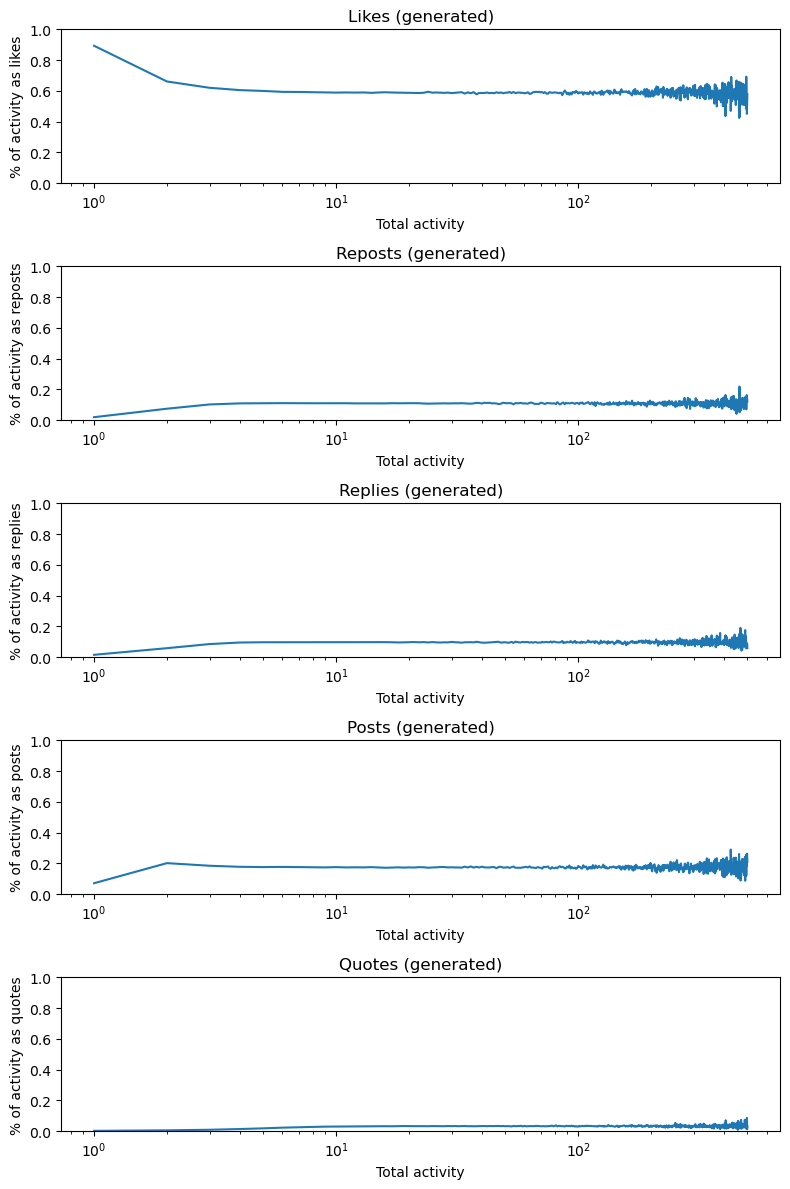

In [7]:
fig, (ax1, ax2, ax3, ax4, ax5) = plt.subplots(5, 1, figsize=(8, 12))

ax1.plot(x, gen_likes_m_y)
ax1.set_title("Likes (generated)")
ax1.set_xlabel("Total activity")
ax1.set_ylabel("% of activity as likes")
ax1.set_xscale("log")
ax1.set_ylim(0, 1)

ax2.plot(x, gen_reposts_m_y)
ax2.set_title("Reposts (generated)")
ax2.set_xlabel("Total activity")
ax2.set_ylabel("% of activity as reposts")
ax2.set_xscale("log")
ax2.set_ylim(0, 1)

ax3.plot(x, gen_replies_m_y)
ax3.set_title("Replies (generated)")
ax3.set_xlabel("Total activity")
ax3.set_ylabel("% of activity as replies")
ax3.set_xscale("log")
ax3.set_ylim(0, 1)

ax4.plot(x, gen_posts_m_y)
ax4.set_title("Posts (generated)")
ax4.set_xlabel("Total activity")
ax4.set_ylabel("% of activity as posts")
ax4.set_xscale("log")
ax4.set_ylim(0, 1)

ax5.plot(x, gen_quotes_m_y)
ax5.set_title("Quotes (generated)")
ax5.set_xlabel("Total activity")
ax5.set_ylabel("% of activity as quotes")
ax5.set_xscale("log")
ax5.set_ylim(0, 1)

plt.tight_layout()
plt.show()

## 3b) Reproduction steps

Provide minimal steps so a new researcher can reproduce the analysis.

1. Ensure `path = "YOUR_PATH_HERE/2025-05-01.json.gz"` is set correctly
2. Run this notebook top-to-bottom to reproduce the plots and fitted parameters.

## 4) Results

Mean percentage and standard deviation for each event type.

In [8]:
print(likes_m, reposts_m, replies_m, posts_m, quotes_m)
print(likes_s, reposts_s, replies_s, posts_s, quotes_s)

0.6915118327290447 0.0815232983022833 0.065723841705132 0.15068090071198412 0.010560126551555762
0.36454652573865576 0.18122663495827296 0.16981072168932315 0.3124205094831243 0.06587685283794088


## 5) Change log

Record updates so future changes are traceable.

- `2026-10-08`: Made small change to the way quotes are labeled from the Bluesky firehose since it was inaccurate. Updated the generation method to better match the new system.